In [82]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path



In [83]:
RAW_PATH = Path("../data/raw")

CLEANED_PATH = Path("../data/cleaned")

CLEANED_PATH.mkdir(parents=True, exist_ok=True)

print("Raw folder:", RAW_PATH)
print("Cleaned folder:", CLEANED_PATH)

Raw folder: ..\data\raw
Cleaned folder: ..\data\cleaned


In [84]:
customers = pd.read_csv(RAW_PATH / "olist_customers_dataset.csv")

geolocation = pd.read_csv(RAW_PATH / "olist_geolocation_dataset.csv")

order_items = pd.read_csv(RAW_PATH / "olist_order_items_dataset.csv")

payments = pd.read_csv(RAW_PATH / "olist_order_payments_dataset.csv")

reviews = pd.read_csv(RAW_PATH / "olist_order_reviews_dataset.csv")

orders = pd.read_csv(RAW_PATH / "olist_orders_dataset.csv")

products = pd.read_csv(RAW_PATH / "olist_products_dataset.csv")

sellers = pd.read_csv(RAW_PATH / "olist_sellers_dataset.csv")

category_translation = pd.read_csv(
    RAW_PATH / "product_category_name_translation.csv"
)

print("All nine datasets loaded successfully!")

All nine datasets loaded successfully!


In [85]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

for name, df in datasets.items():

    print(f"\n{name}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Customers
Rows: 99441
Columns: 5

Geolocation
Rows: 1000163
Columns: 5

Order Items
Rows: 112650
Columns: 7

Payments
Rows: 103886
Columns: 5

Reviews
Rows: 99224
Columns: 7

Orders
Rows: 99441
Columns: 8

Products
Rows: 32951
Columns: 9

Sellers
Rows: 3095
Columns: 4

Category Translation
Rows: 71
Columns: 2


In [86]:
for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name)
    display(df.head())


Customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



Order Items


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (8 outputs left out)


Sellers


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



Category Translation


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [87]:
for name, df in datasets.items():

    print("\n", "=" * 50)
    print("Dataset:", name)

    df.info()


Dataset: Customers
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Dataset: Geolocation
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolo

In [88]:
missing_report = []

for name, df in datasets.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        missing_percentage = (
            missing_count / len(df)
        ) * 100

        missing_report.append({
            "Dataset": name,
            "Column": column,
            "Missing Values": missing_count,
            "Missing Percentage": round(
                missing_percentage, 2
            )
        })

missing_df = pd.DataFrame(missing_report)

missing_df = missing_df[
    missing_df["Missing Values"] > 0
]

display(missing_df)

,Dataset,Column,Missing Values,Missing Percentage
25,Reviews,review_comment_title,87656,88.34
26,Reviews,review_comment_message,58247,58.70
33,Orders,order_approved_at,160,0.16
34,Orders,order_delivered_carrier_date,1783,1.79
35,Orders,order_delivered_customer_date,2965,2.98
38,Products,product_category_name,610,1.85
39,Products,product_name_lenght,610,1.85
40,Products,product_description_lenght,610,1.85
41,Products,product_photos_qty,610,1.85
42,Products,product_weight_g,2,0.01


In [89]:
duplicate_report = []

for name, df in datasets.items():

    duplicate_count = df.duplicated().sum()

    duplicate_report.append({
        "Dataset": name,
        "Total Records": len(df),
        "Duplicate Records": duplicate_count
    })

duplicate_df = pd.DataFrame(duplicate_report)

display(duplicate_df)

,Dataset,Total Records,Duplicate Records
0,Customers,99441,0
1,Geolocation,1000163,261831
2,Order Items,112650,0
3,Payments,103886,0
4,Reviews,99224,0
5,Orders,99441,0
6,Products,32951,0
7,Sellers,3095,0
8,Category Translation,71,0


In [90]:
print("Negative Quantity:")
print((order_items["order_item_id"] < 0).sum())

print("\nNegative Product Price:")
print((order_items["price"] < 0).sum())

print("\nNegative Freight Value:")
print((order_items["freight_value"] < 0).sum())

print("\nInvalid Review Scores:")
print((~reviews["review_score"].between(1, 5)).sum())

Negative Quantity:
0

Negative Product Price:
0

Negative Freight Value:
0

Invalid Review Scores:
0


In [91]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:

    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

print(orders[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [92]:
cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

print("Working copies created successfully!")

Working copies created successfully!


In [93]:
products_clean = cleaned_datasets["Products"]

products_clean["product_category_name"] = (
    products_clean["product_category_name"]
    .fillna("Unknown")
)

print("Missing product categories handled.")

print(
    products_clean["product_category_name"]
    .isnull().sum()
)

Missing product categories handled.
0


In [94]:
product_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for col in product_columns:

    products_clean[col + "_missing"] = (
        products_clean[col].isnull().astype(int)
    )

print("Missing-value indicators created!")

Missing-value indicators created!


In [95]:
for name, df in cleaned_datasets.items():

    print("\nDataset:", name)

    print(df.isnull().sum()[df.isnull().sum() > 0])


Dataset: Customers
Series([], dtype: int64)

Dataset: Geolocation
Series([], dtype: int64)

Dataset: Order Items
Series([], dtype: int64)

Dataset: Payments
Series([], dtype: int64)

Dataset: Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Dataset: Orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Dataset: Products
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Dataset: Sellers
Series([], dtype: int64)

Dataset: Category Translation
Series([], dtype: int64)


In [96]:
geo_clean = cleaned_datasets["Geolocation"]

before = len(geo_clean)

geo_clean = geo_clean.drop_duplicates()

after = len(geo_clean)

removed = before - after

cleaned_datasets["Geolocation"] = geo_clean

print("Records before cleaning:", before)
print("Records after cleaning:", after)
print("Duplicates removed:", removed)

Records before cleaning: 1000163
Records after cleaning: 738332
Duplicates removed: 261831


In [97]:
for name, df in cleaned_datasets.items():

    print(
        name,
        "Remaining duplicates:",
        df.duplicated().sum()
    )

Customers Remaining duplicates: 0
Geolocation Remaining duplicates: 0
Order Items Remaining duplicates: 0
Payments Remaining duplicates: 0
Reviews Remaining duplicates: 0
Orders Remaining duplicates: 0
Products Remaining duplicates: 0
Sellers Remaining duplicates: 0
Category Translation Remaining duplicates: 0


In [98]:
items_clean = cleaned_datasets["Order Items"]

print("Negative prices:",
      (items_clean["price"] < 0).sum())

print("Zero prices:",
      (items_clean["price"] == 0).sum())

print("Negative freight values:",
      (items_clean["freight_value"] < 0).sum())

Negative prices: 0
Zero prices: 0
Negative freight values: 0


In [99]:
payments_clean = cleaned_datasets["Payments"]

print(
    "Negative payment values:",
    (payments_clean["payment_value"] < 0).sum()
)

print(
    "Invalid payment installments:",
    (payments_clean["payment_installments"] <= 0).sum()
)

Negative payment values: 0
Invalid payment installments: 2


In [100]:
reviews_clean = cleaned_datasets["Reviews"]

print(
    "Invalid review scores:",
    (~reviews_clean["review_score"].between(1, 5)).sum()
)

Invalid review scores: 0


In [101]:
orders_clean = cleaned_datasets["Orders"]

orders_clean["order_purchase_timestamp"] = pd.to_datetime(
    orders_clean["order_purchase_timestamp"],
    errors="coerce"
)

orders_clean["order_delivered_customer_date"] = pd.to_datetime(
    orders_clean["order_delivered_customer_date"],
    errors="coerce"
)

orders_clean["order_estimated_delivery_date"] = pd.to_datetime(
    orders_clean["order_estimated_delivery_date"],
    errors="coerce"
)

invalid_delivery_dates = orders_clean[
    orders_clean["order_delivered_customer_date"].notna() &
    (
        orders_clean["order_delivered_customer_date"] <
        orders_clean["order_purchase_timestamp"]
    )
]

print("Invalid delivery timelines:", len(invalid_delivery_dates))

Invalid delivery timelines: 0


In [102]:
for name, df in cleaned_datasets.items():

    filename = name.lower().replace(" ", "_") + ".csv"

    df.to_csv(
        CLEANED_PATH / filename,
        index=False
    )

    print("Saved:", filename)

print("\nAll cleaned datasets exported successfully!")

Saved: customers.csv
Saved: geolocation.csv
Saved: order_items.csv
Saved: payments.csv
Saved: reviews.csv
Saved: orders.csv
Saved: products.csv
Saved: sellers.csv
Saved: category_translation.csv

All cleaned datasets exported successfully!


In [103]:
cleaning_summary = []

for name, df in cleaned_datasets.items():

    original_df = datasets[name]

    cleaning_summary.append({
        "Dataset": name,
        "Original Rows": len(original_df),
        "Cleaned Rows": len(df),
        "Rows Removed": len(original_df) - len(df),
        "Original Columns": len(original_df.columns),
        "Cleaned Columns": len(df.columns),
        "Remaining Missing Values": df.isnull().sum().sum(),
        "Remaining Duplicates": df.duplicated().sum()
    })

cleaning_report = pd.DataFrame(cleaning_summary)

display(cleaning_report)
cleaning_report.to_csv(
    "../outputs/cleaning_summary.csv",
    index=False
)

,Dataset,Original Rows,Cleaned Rows,Rows Removed,Original Columns,Cleaned Columns,Remaining Missing Values,Remaining Duplicates
0,Customers,99441,99441,0,5,5,0,0
1,Geolocation,1000163,738332,261831,5,5,0,0
2,Order Items,112650,112650,0,7,7,0,0
3,Payments,103886,103886,0,5,5,0,0
4,Reviews,99224,99224,0,7,7,145903,0
5,Orders,99441,99441,0,8,8,4908,0
6,Products,32951,32951,0,9,16,1838,0
7,Sellers,3095,3095,0,4,4,0,0
8,Category Translation,71,71,0,2,2,0,0


In [104]:
from pathlib import Path

OUTPUT_PATH = Path("../outputs")
REPORT_PATH = OUTPUT_PATH / "reports"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)

print("Output folders created successfully!")

Output folders created successfully!


In [105]:
missing_df.to_csv(
    REPORT_PATH / "missing_values_report.csv",
    index=False
)

print("Missing value report saved!")

Missing value report saved!


In [106]:
duplicate_df.to_csv(
    REPORT_PATH / "duplicate_analysis.csv",
    index=False
)

print("Duplicate analysis saved!")

Duplicate analysis saved!


In [107]:
cleaning_report.to_csv(
    REPORT_PATH / "cleaning_summary.csv",
    index=False
)

print("Cleaning summary saved!")

Cleaning summary saved!


In [108]:
validation_results = []

# Order item checks
validation_results.extend([
    {
        "Dataset": "Order Items",
        "Check": "Negative prices",
        "Invalid Records": (items_clean["price"] < 0).sum()
    },
    {
        "Dataset": "Order Items",
        "Check": "Negative freight values",
        "Invalid Records": (items_clean["freight_value"] < 0).sum()
    },
    {
        "Dataset": "Payments",
        "Check": "Negative payment values",
        "Invalid Records": (payments_clean["payment_value"] < 0).sum()
    },
    {
        "Dataset": "Payments",
        "Check": "Invalid installments",
        "Invalid Records": (payments_clean["payment_installments"] <= 0).sum()
    },
    {
        "Dataset": "Reviews",
        "Check": "Review score outside 1-5",
        "Invalid Records": (~reviews_clean["review_score"].between(1, 5)).sum()
    },
    {
        "Dataset": "Orders",
        "Check": "Delivery before purchase",
        "Invalid Records": len(invalid_delivery_dates)
    }
])

validation_report = pd.DataFrame(validation_results)

display(validation_report)

,Dataset,Check,Invalid Records
0,Order Items,Negative prices,0
1,Order Items,Negative freight values,0
2,Payments,Negative payment values,0
3,Payments,Invalid installments,2
4,Reviews,Review score outside 1-5,0
5,Orders,Delivery before purchase,0


In [109]:
validation_report.to_csv(
    REPORT_PATH / "data_validation_report.csv",
    index=False
)

print("Validation report saved!")

Validation report saved!


In [110]:
for name, df in cleaned_datasets.items():

    filename = name.lower().replace(" ", "_") + ".csv"

    file_path = CLEANED_PATH / filename

    if file_path.exists():

        check_df = pd.read_csv(file_path)

        print(
            f"{filename}: Verified | "
            f"Rows: {len(check_df)} | "
            f"Columns: {len(check_df.columns)}"
        )

    else:
        print(f"File missing: {filename}")

customers.csv: Verified | Rows: 99441 | Columns: 5
geolocation.csv: Verified | Rows: 738332 | Columns: 5
order_items.csv: Verified | Rows: 112650 | Columns: 7
payments.csv: Verified | Rows: 103886 | Columns: 5
reviews.csv: Verified | Rows: 99224 | Columns: 7
orders.csv: Verified | Rows: 99441 | Columns: 8
products.csv: Verified | Rows: 32951 | Columns: 16
sellers.csv: Verified | Rows: 3095 | Columns: 4
category_translation.csv: Verified | Rows: 71 | Columns: 2


In [111]:
cleaning_decisions = pd.DataFrame([
    {
        "Dataset": "Products",
        "Column": "product_category_name",
        "Decision": "Filled missing values with Unknown",
        "Reason": "Preserved product records"
    },
    {
        "Dataset": "Products",
        "Columns": "Product dimension columns",
        "Decision": "Created missing-value indicators",
        "Reason": "Preserved missing information for investigation"
    },
    {
        "Dataset": "Geolocation",
        "Column": "All columns",
        "Decision": "Removed fully duplicated rows",
        "Reason": "Avoided redundant identical records"
    },
    {
        "Dataset": "Orders",
        "Columns": "Delivery timestamps",
        "Decision": "Retained missing dates",
        "Reason": "Missing delivery information may represent undelivered orders"
    },
    {
        "Dataset": "Reviews",
        "Columns": "Review comments",
        "Decision": "Retained missing comments",
        "Reason": "Review text is optional"
    }
])

display(cleaning_decisions)

cleaning_decisions.to_csv(
    REPORT_PATH / "cleaning_decisions.csv",
    index=False
)

,Dataset,Column,Decision,Reason,Columns
0,Products,product_category_name,Filled missing values with Unknown,Preserved product records,NaN
1,Products,NaN,Created missing-value indicators,Preserved missing information for investigation,Product dimension columns
2,Geolocation,All columns,Removed fully duplicated rows,Avoided redundant identical records,NaN
3,Orders,NaN,Retained missing dates,Missing delivery information may represent und...,Delivery timestamps
4,Reviews,NaN,Retained missing comments,Review text is optional,Review comments


In [112]:
# ********************TASK-2 SALES DATA ANALYSIS *******************


customers = pd.read_csv(CLEANED_PATH / "customers.csv")
orders = pd.read_csv(CLEANED_PATH / "orders.csv")
order_items = pd.read_csv(CLEANED_PATH / "order_items.csv")
payments = pd.read_csv(CLEANED_PATH / "payments.csv")
reviews = pd.read_csv(CLEANED_PATH / "reviews.csv")
products = pd.read_csv(CLEANED_PATH / "products.csv")
sellers = pd.read_csv(CLEANED_PATH / "sellers.csv")
geolocation = pd.read_csv(CLEANED_PATH / "geolocation.csv")
category_translation = pd.read_csv(
    CLEANED_PATH / "category_translation.csv"
)

print("All cleaned datasets loaded successfully!")


All cleaned datasets loaded successfully!


In [113]:
print("Order Status Distribution")

display(
    orders["order_status"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "index": "Order Status",
        "order_status": "Total Orders"
    })
)

Order Status Distribution


,Total Orders,count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [114]:
print("Orders Dataset:")
display(orders.head())

print("Order Items Dataset:")
display(order_items.head())

print("Products Dataset:")
display(products.head())

Orders Dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Order Items Dataset:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


Products Dataset:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_name_lenght_missing,product_description_lenght_missing,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0,0,0,0,0,0,0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0,0,0,0,0,0,0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0,0,0,0,0,0,0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0,0,0,0,0,0,0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0,0,0,0,0,0,0


In [115]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Total Delivered Orders:", len(delivered_orders))

Total Delivered Orders: 96478


In [116]:
sales_data = order_items.merge(
    delivered_orders,
    on="order_id",
    how="inner"
)

print("Sales data shape:", sales_data.shape)

display(sales_data.head())

Sales data shape: (110197, 14)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17


In [117]:
sales_data = sales_data.merge(
    products,
    on="product_id",
    how="left"
)

print("Product information merged successfully!")

display(sales_data.head())

Product information merged successfully!


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_length_cm,product_height_cm,product_width_cm,product_name_lenght_missing,product_description_lenght_missing,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,28.0,9.0,14.0,0,0,0,0,0,0,0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,50.0,30.0,40.0,0,0,0,0,0,0,0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,33.0,13.0,33.0,0,0,0,0,0,0,0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,16.0,10.0,15.0,0,0,0,0,0,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,35.0,40.0,30.0,0,0,0,0,0,0,0


In [118]:
sales_data = sales_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

sales_data["product_category_name_english"] = (
    sales_data["product_category_name_english"]
    .fillna("Unknown")
)

print("Category translation completed!")

display(
    sales_data[
        ["order_id", "product_id",
         "product_category_name_english",
         "price", "freight_value"]
    ].head()
)

Category translation completed!


,order_id,product_id,product_category_name_english,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,perfumery,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,garden_tools,199.90,18.14


In [119]:
total_revenue = sales_data["price"].sum()

print("Total Revenue: ₹", round(total_revenue, 2))

Total Revenue: ₹ 13221498.11


In [120]:
total_orders = sales_data["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 96478


In [121]:
average_order_value = total_revenue / total_orders

print("Average Order Value: ₹",
      round(average_order_value, 2))

Average Order Value: ₹ 137.04


In [122]:
total_units_sold = len(sales_data)

print("Total Units Sold:", total_units_sold)

Total Units Sold: 110197


In [123]:
category_sales = (
    sales_data.groupby("product_category_name_english")
    ["price"]
    .sum()
    .sort_values(ascending=False)
)

top_category = category_sales.index[0]

print("Top-Selling Category:", top_category)
print("Category Revenue: ₹", round(category_sales.iloc[0], 2))

Top-Selling Category: health_beauty
Category Revenue: ₹ 1233131.72


In [124]:
product_sales = (
    sales_data.groupby("product_id")["price"]
    .sum()
    .sort_values(ascending=False)
)

top_product = product_sales.index[0]

print("Top Product ID:", top_product)
print("Product Revenue: ₹", round(product_sales.iloc[0], 2))

Top Product ID: bb50f2e236e5eea0100680137654686c
Product Revenue: ₹ 63560.0


In [125]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category",
        "Top Revenue-Generating Product"
    ],

    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        total_units_sold,
        top_category,
        top_product
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue,13221498.11
1,Total Orders,96478
2,Average Order Value,137.04
3,Total Units Sold,110197
4,Top-Selling Category,health_beauty
5,Top Revenue-Generating Product,bb50f2e236e5eea0100680137654686c


In [126]:
kpi_summary.to_csv(
    REPORT_PATH / "sales_kpi_summary.csv",
    index=False
)

print("KPI report saved successfully!")

KPI report saved successfully!


In [127]:
sales_data.to_csv(
    CLEANED_PATH / "combined_sales_data.csv",
    index=False
)

print("Combined sales dataset saved!")

Combined sales dataset saved!


In [128]:
sales_data["order_purchase_timestamp"] = pd.to_datetime(
    sales_data["order_purchase_timestamp"],
    errors="coerce"
)

sales_data["month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

print("Date conversion completed!")

Date conversion completed!


In [129]:
monthly_sales = (
    sales_data.groupby("month")["price"]
    .sum()
    .reset_index()
)

monthly_sales["month"] = monthly_sales["month"].astype(str)

monthly_sales.columns = ["Month", "Revenue"]

display(monthly_sales)

,Month,Revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


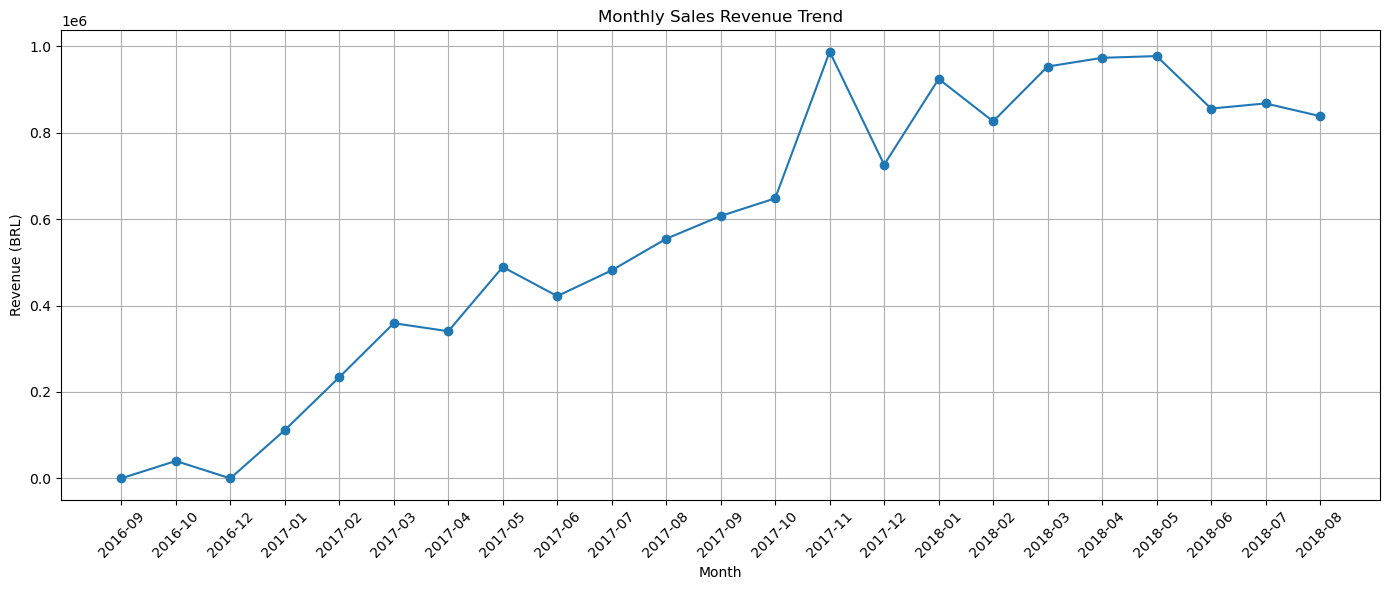

In [130]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [131]:
category_revenue = (
    sales_data.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_revenue.columns = [
    "Category",
    "Revenue"
]

display(category_revenue.head(10))

,Category,Revenue
0,health_beauty,1233131.72
1,watches_gifts,1166176.98
2,bed_bath_table,1023434.76
3,sports_leisure,954852.55
4,computers_accessories,888724.61
5,furniture_decor,711927.69
6,housewares,615628.69
7,cool_stuff,610204.10
8,auto,578966.65
9,toys,471286.48


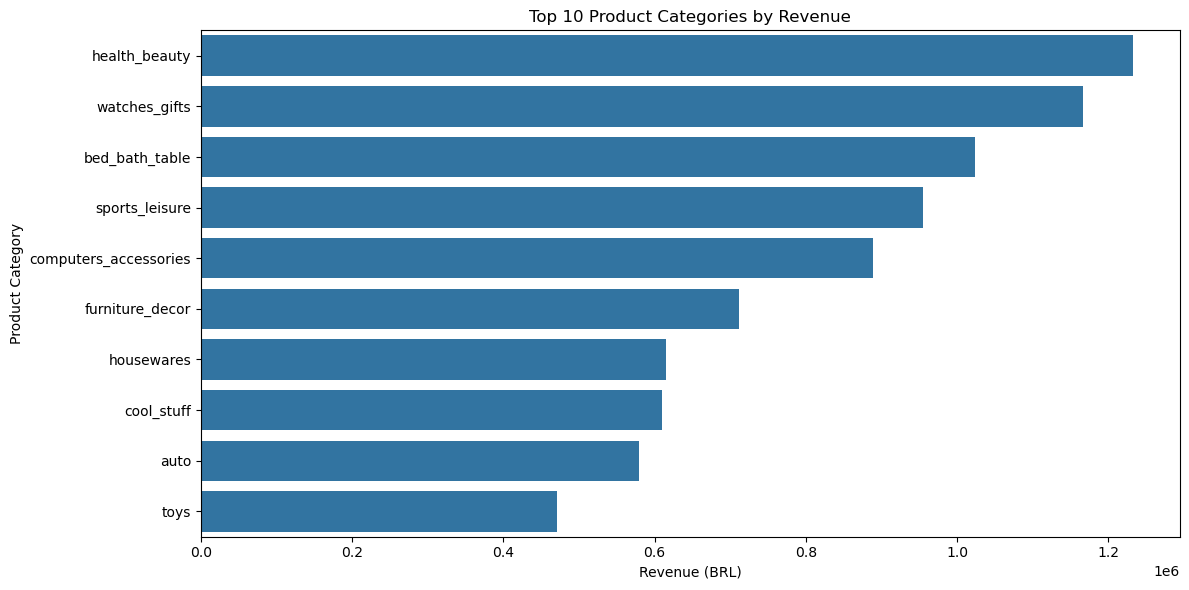

In [132]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue.head(10),
    x="Revenue",
    y="Category"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [133]:
customer_sales = sales_data.merge(
    customers[
        ["customer_id", "customer_city", "customer_state",
         "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

display(customer_sales.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing,product_category_name_english,month,customer_city,customer_state,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,0,0,0,0,0,cool_stuff,2017-09,campos dos goytacazes,RJ,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,0,0,0,0,0,pet_shop,2017-04,santa fe do sul,SP,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,0,0,0,0,0,furniture_decor,2018-01,para de minas,MG,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,0,0,0,0,0,perfumery,2018-08,atibaia,SP,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,0,0,0,0,0,garden_tools,2017-02,varzea paulista,SP,64b576fb70d441e8f1b2d7d446e483c5


In [134]:
state_sales = (
    customer_sales.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

state_sales.columns = ["State", "Revenue"]

display(state_sales.head(10))

,State,Revenue
0,SP,5067633.16
1,RJ,1759651.13
2,MG,1552481.83
3,RS,728897.47
4,PR,666063.51
5,SC,507012.13
6,BA,493584.14
7,DF,296498.41
8,GO,282836.70
9,ES,268643.45


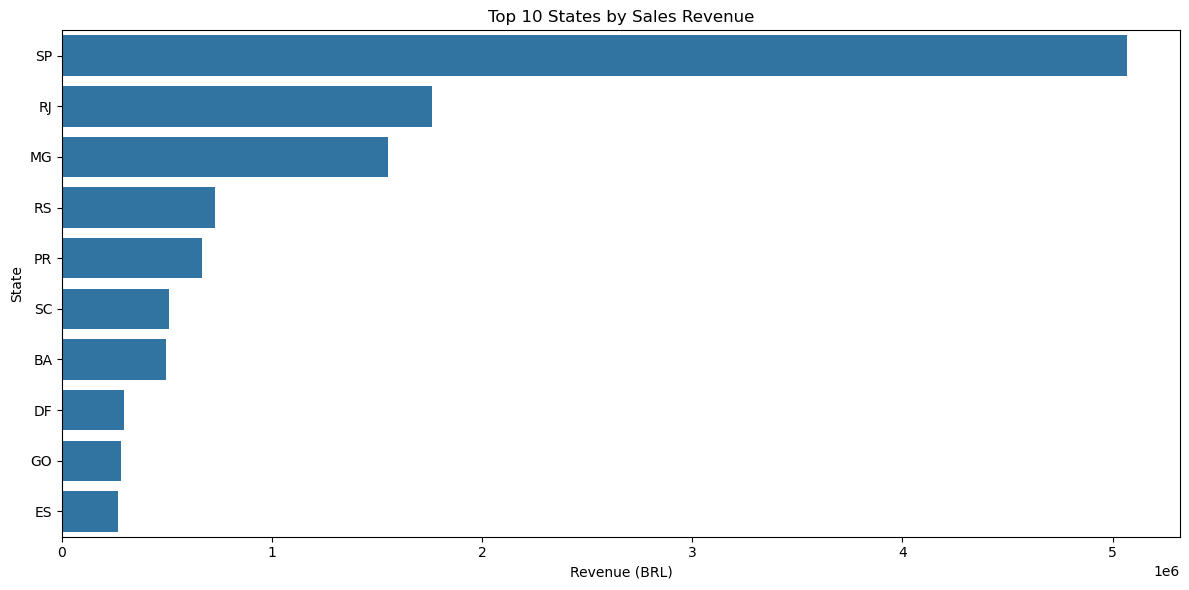

In [135]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_sales.head(10),
    x="Revenue",
    y="State"
)

plt.title("Top 10 States by Sales Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [136]:
total_customers = customer_sales["customer_unique_id"].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 93358


In [137]:
customer_orders = (
    customer_sales.groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index()
)

customer_orders.columns = [
    "Customer ID",
    "Total Orders"
]

repeat_customers = customer_orders[
    customer_orders["Total Orders"] > 1
]

print("Repeat Customers:", len(repeat_customers))

print(
    "One-Time Customers:",
    len(customer_orders) - len(repeat_customers)
)

Repeat Customers: 2801
One-Time Customers: 90557


In [138]:
repeat_customer_percentage = (
    len(repeat_customers) / len(customer_orders)
) * 100

print(
    "Repeat Customer Percentage:",
    round(repeat_customer_percentage, 2),
    "%"
)

Repeat Customer Percentage: 3.0 %


In [139]:
purchase_distribution = (
    customer_orders["Total Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

purchase_distribution.columns = [
    "Number of Orders",
    "Number of Customers"
]

display(purchase_distribution.head(10))

,Number of Orders,Number of Customers
0,1,90557
1,2,2573
2,3,181
3,4,28
4,5,9
5,6,5
6,7,3
7,9,1
8,15,1


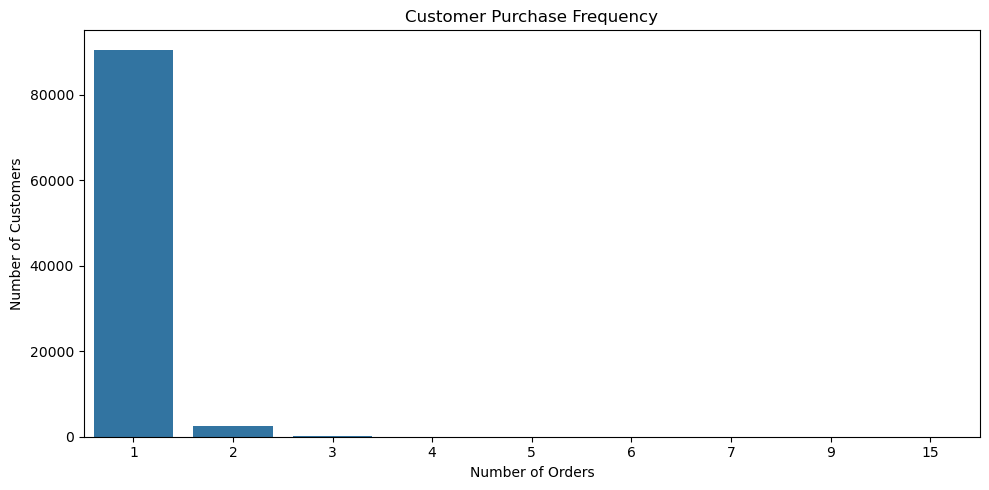

In [140]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=purchase_distribution.head(10),
    x="Number of Orders",
    y="Number of Customers"
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [141]:
payment_analysis = (
    payments.groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

payment_analysis.columns = [
    "Payment Method",
    "Total Payment"
]

display(payment_analysis)

,Payment Method,Total Payment
0,credit_card,12542084.19
1,boleto,2869361.27
2,voucher,379436.87
3,debit_card,217989.79
4,not_defined,0.00


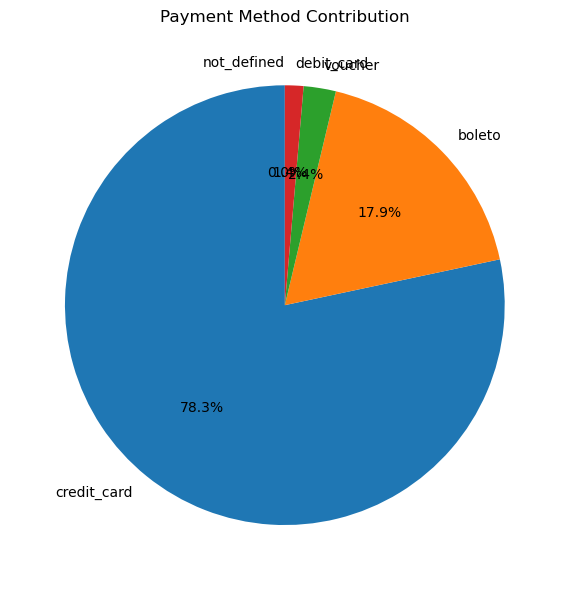

In [142]:
plt.figure(figsize=(8, 6))

plt.pie(
    payment_analysis["Total Payment"],
    labels=payment_analysis["Payment Method"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Contribution")

plt.tight_layout()
plt.show()

In [143]:
print("========== BUSINESS INSIGHTS ==========")

print(
    "\n1. Highest Revenue Month:",
    monthly_sales.loc[
        monthly_sales["Revenue"].idxmax(), "Month"
    ]
)

print(
    "\n2. Highest Revenue Category:",
    category_revenue.iloc[0]["Category"]
)

print(
    "\n3. Highest Revenue State:",
    state_sales.iloc[0]["State"]
)

print(
    "\n4. Total Unique Customers:",
    total_customers
)

print(
    "\n5. Repeat Customer Percentage:",
    round(repeat_customer_percentage, 2), "%"
)

print(
    "\n6. Most Used Payment Method:",
    payments["payment_type"].mode()[0]
)

print(
    "\n7. Total Delivered Sales Revenue:",
    round(total_revenue, 2)
)

========== BUSINESS INSIGHTS ==========

1. Highest Revenue Month: 2017-11

2. Highest Revenue Category: health_beauty

3. Highest Revenue State: SP

4. Total Unique Customers: 93358

5. Repeat Customer Percentage: 3.0 %

6. Most Used Payment Method: credit_card

7. Total Delivered Sales Revenue: 13221498.11


In [144]:
monthly_sales.to_csv(
    REPORT_PATH / "monthly_sales_trend.csv",
    index=False
)

In [145]:
category_revenue.to_csv(
    REPORT_PATH / "category_revenue.csv",
    index=False
)

In [146]:
state_sales.to_csv(
    REPORT_PATH / "state_sales.csv",
    index=False
)

In [147]:
customer_orders.to_csv(
    REPORT_PATH / "customer_purchase_analysis.csv",
    index=False
)

In [148]:
payment_analysis.to_csv(
    REPORT_PATH / "payment_analysis.csv",
    index=False
)

print("All Task 2 analysis reports saved successfully!")

All Task 2 analysis reports saved successfully!


In [149]:
from pathlib import Path

CHART_PATH = Path("../outputs/charts")
DASHBOARD_PATH = Path("../outputs/dashboard")

CHART_PATH.mkdir(parents=True, exist_ok=True)
DASHBOARD_PATH.mkdir(parents=True, exist_ok=True)

print("Visualization folders created!")

Visualization folders created!


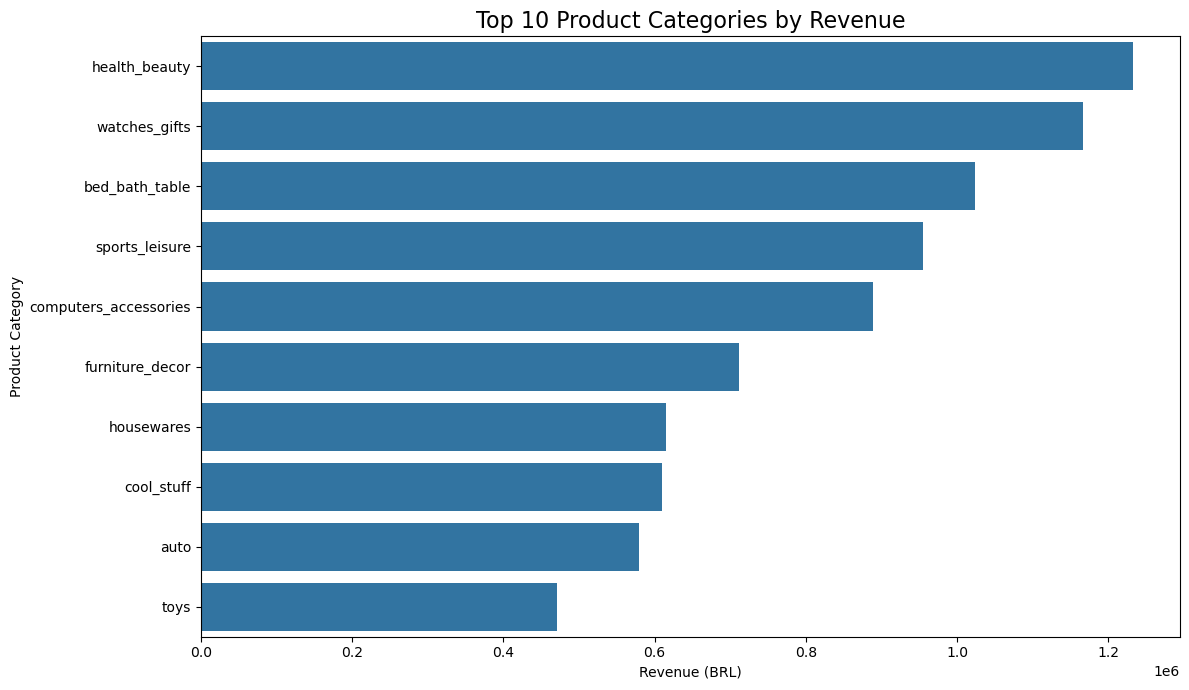

In [150]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_revenue.head(10),
    x="Revenue",
    y="Category"
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=16
)

plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()

plt.savefig(
    CHART_PATH / "top_10_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

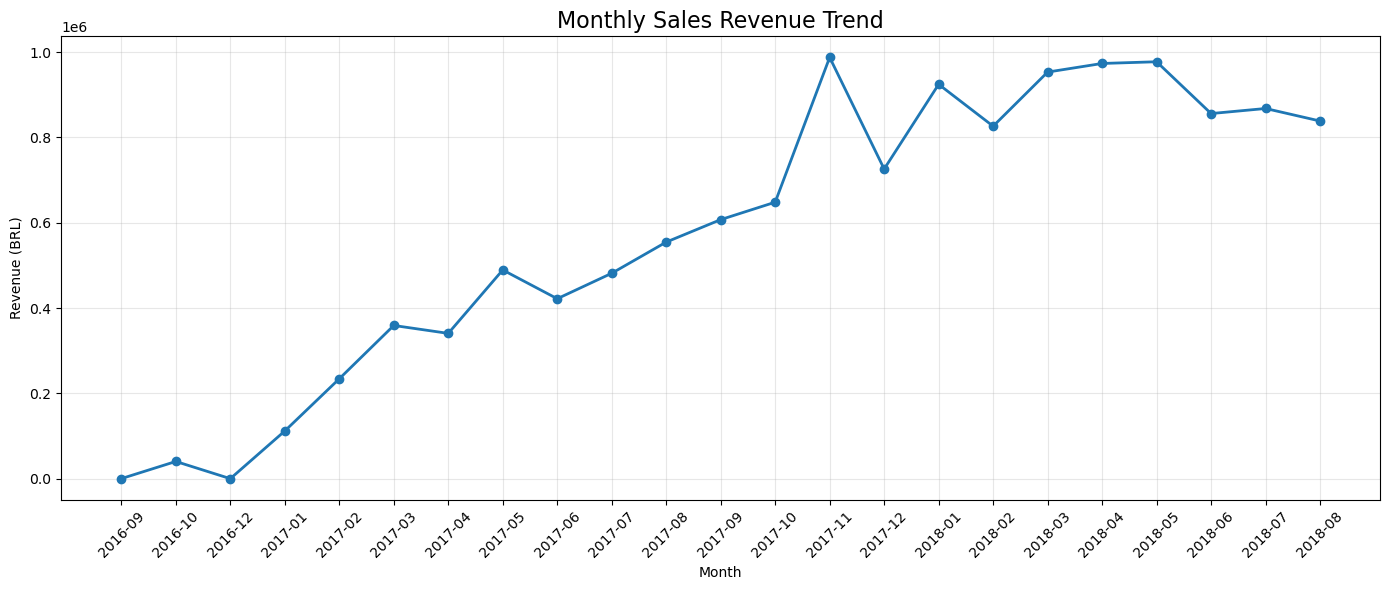

In [151]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Sales Revenue Trend",
    fontsize=16
)

plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")

plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_PATH / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

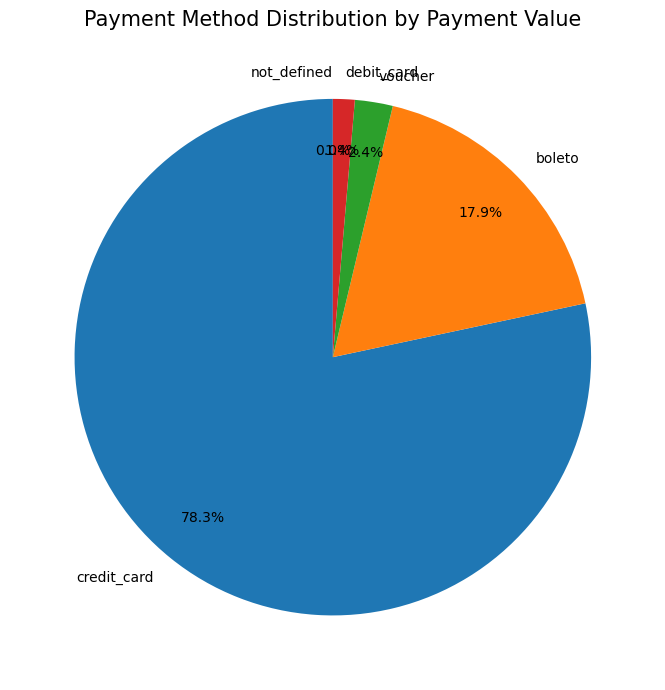

In [152]:
plt.figure(figsize=(9, 7))

plt.pie(
    payment_analysis["Total Payment"],
    labels=payment_analysis["Payment Method"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8
)

plt.title(
    "Payment Method Distribution by Payment Value",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    CHART_PATH / "payment_method_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\varat\AppData\Local\Temp\ipykernel_21064\1852928800.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


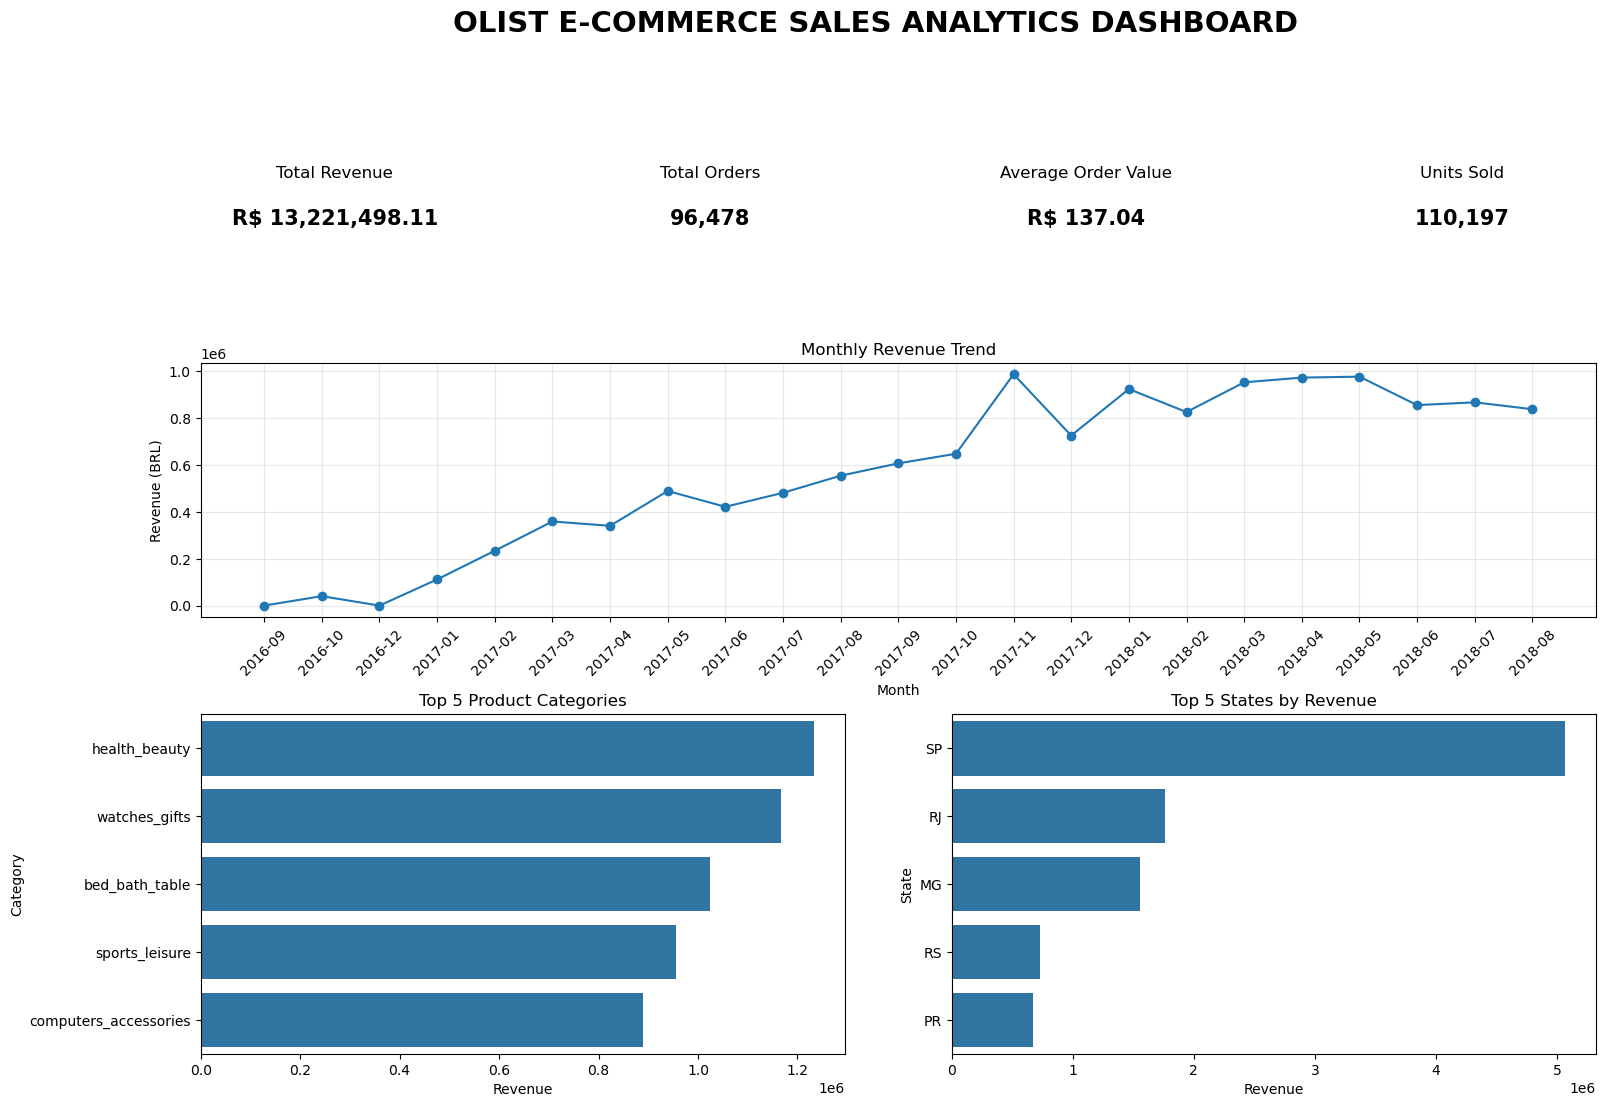

In [153]:
fig = plt.figure(figsize=(18, 12))

fig.suptitle(
    "OLIST E-COMMERCE SALES ANALYTICS DASHBOARD",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.8, 1.5, 2],
    hspace=0.4,
    wspace=0.4
)

# KPI Cards
kpis = [
    ("Total Revenue", f"R$ {total_revenue:,.2f}"),
    ("Total Orders", f"{total_orders:,}"),
    ("Average Order Value", f"R$ {average_order_value:,.2f}"),
    ("Units Sold", f"{total_units_sold:,}")
]

for i, (title, value) in enumerate(kpis):

    ax = fig.add_subplot(gs[0, i])

    ax.text(
        0.5, 0.65,
        title,
        ha="center",
        fontsize=12
    )

    ax.text(
        0.5, 0.3,
        value,
        ha="center",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_axis_off()

# Monthly Sales Trend
ax1 = fig.add_subplot(gs[1, :])

ax1.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)

ax1.set_title("Monthly Revenue Trend")
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue (BRL)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(True, alpha=0.3)

# Top Categories
ax2 = fig.add_subplot(gs[2, :2])

sns.barplot(
    data=category_revenue.head(5),
    x="Revenue",
    y="Category",
    ax=ax2
)

ax2.set_title("Top 5 Product Categories")

# Top States
ax3 = fig.add_subplot(gs[2, 2:])

sns.barplot(
    data=state_sales.head(5),
    x="Revenue",
    y="State",
    ax=ax3
)

ax3.set_title("Top 5 States by Revenue")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    DASHBOARD_PATH / "olist_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [154]:
print("========== CUSTOMER INSIGHTS ==========")

print("Total Unique Customers:", total_customers)

print("Repeat Customers:", len(repeat_customers))

print(
    "Repeat Customer Percentage:",
    round(repeat_customer_percentage, 2),
    "%"
)

print(
    "One-Time Customers:",
    len(customer_orders) - len(repeat_customers)
)

========== CUSTOMER INSIGHTS ==========
Total Unique Customers: 93358
Repeat Customers: 2801
Repeat Customer Percentage: 3.0 %
One-Time Customers: 90557


In [155]:
visualization_summary = pd.DataFrame({
    "Visualization": [
        "Bar Chart",
        "Line Chart",
        "Pie Chart",
        "Dashboard"
    ],

    "File Name": [
        "top_10_categories.png",
        "monthly_sales_trend.png",
        "payment_method_distribution.png",
        "olist_sales_dashboard.png"
    ],

    "Purpose": [
        "Compare category revenue",
        "Analyze monthly sales trends",
        "Analyze payment method contribution",
        "Summarize overall business performance"
    ]
})

display(visualization_summary)

,Visualization,File Name,Purpose
0,Bar Chart,top_10_categories.png,Compare category revenue
1,Line Chart,monthly_sales_trend.png,Analyze monthly sales trends
2,Pie Chart,payment_method_distribution.png,Analyze payment method contribution
3,Dashboard,olist_sales_dashboard.png,Summarize overall business performance


In [156]:
visualization_summary.to_csv(
    REPORT_PATH / "visualization_summary.csv",
    index=False
)

print("Visualization summary exported successfully!")

Visualization summary exported successfully!


In [157]:
sales_data["order_purchase_timestamp"] = pd.to_datetime(
    sales_data["order_purchase_timestamp"],
    errors="coerce"
)

sales_data["month_period"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

monthly_revenue = (
    sales_data.groupby("month_period")["price"].sum()
)

all_months = pd.period_range(
    start=monthly_revenue.index.min(),
    end=monthly_revenue.index.max(),
    freq="M"
)

monthly_sales = (
    monthly_revenue.reindex(all_months, fill_value=0)
    .rename_axis("Month")
    .reset_index(name="Revenue")
)

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

display(monthly_sales)

,Month,Revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-11,0.00
3,2016-12,10.90
4,2017-01,111798.36
5,2017-02,234223.40
6,2017-03,359198.85
7,2017-04,340669.68
8,2017-05,489338.25
9,2017-06,421923.37


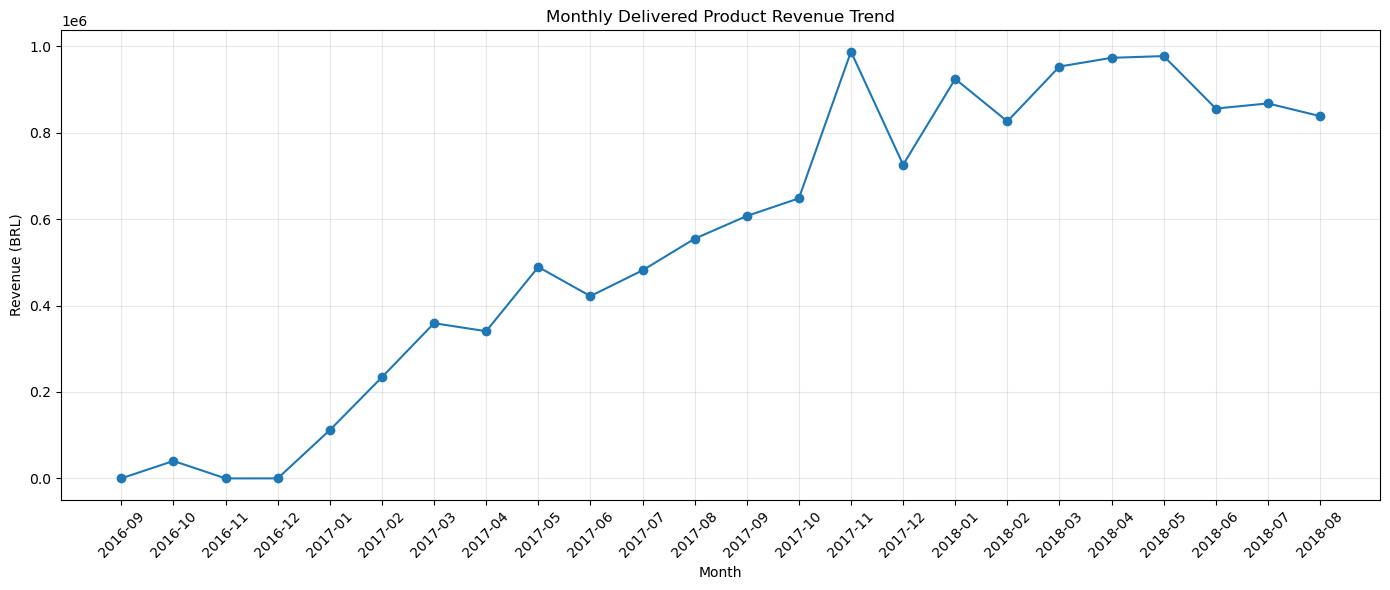

In [158]:
monthly_sales.to_csv(
    REPORT_PATH / "monthly_sales_trend.csv",
    index=False
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Delivered Product Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_PATH / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [159]:
top_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

top_category_row = category_revenue.iloc[0]

top_state_row = state_sales.iloc[0]

top_payment = payment_analysis.iloc[0]

top_5_category_share = (
    category_revenue.head(5)["Revenue"].sum()
    / total_revenue
) * 100

top_state_share = (
    state_sales.iloc[0]["Revenue"]
    / total_revenue
) * 100

business_insights = [
    f"Delivered orders generated product revenue of R$ {total_revenue:,.2f}.",

    f"The analysis identified {total_orders:,} delivered orders.",

    f"The average product revenue per delivered order was R$ {average_order_value:,.2f}.",

    f"The highest-revenue month was {top_month['Month']}.",

    f"{top_category_row['Category']} was the highest revenue-generating product category.",

    f"{top_state_row['State']} generated the highest state-level product revenue.",

    f"The top five product categories contributed {top_5_category_share:.2f}% of delivered product revenue.",

    f"Repeat customers represented {repeat_customer_percentage:.2f}% of unique customers with delivered orders."
]

for i, insight in enumerate(business_insights, 1):
    print(f"{i}. {insight}")

1. Delivered orders generated product revenue of R$ 13,221,498.11.
2. The analysis identified 96,478 delivered orders.
3. The average product revenue per delivered order was R$ 137.04.
4. The highest-revenue month was 2017-11.
5. health_beauty was the highest revenue-generating product category.
6. SP generated the highest state-level product revenue.
7. The top five product categories contributed 39.83% of delivered product revenue.
8. Repeat customers represented 3.00% of unique customers with delivered orders.


In [160]:
insights_df = pd.DataFrame({
    "Observation Number": range(1, 9),
    "Business Insight": business_insights
})

display(insights_df)

insights_df.to_csv(
    REPORT_PATH / "business_insights.csv",
    index=False
)

,Observation Number,Business Insight
0,1,Delivered orders generated product revenue of ...
1,2,"The analysis identified 96,478 delivered orders."
2,3,The average product revenue per delivered orde...
3,4,The highest-revenue month was 2017-11.
4,5,health_beauty was the highest revenue-generati...
5,6,SP generated the highest state-level product r...
6,7,The top five product categories contributed 39...
7,8,Repeat customers represented 3.00% of unique c...


In [161]:
readme_content = """
# Olist E-Commerce Data Analysis
## WeIntern Data Science Internship – Week 1

### Project Overview
This project analyzes the Brazilian Olist E-Commerce dataset.
The objective is to clean raw data, analyze sales performance,
identify customer behavior, and communicate business insights.

### Tasks Completed

#### Task 1: Data Cleaning
- Dataset inspection
- Missing value analysis
- Duplicate detection and removal
- Data validation
- Export of cleaned datasets

#### Task 2: Sales Data Analysis
- Revenue calculation
- Order analysis
- Average Order Value
- Product category analysis
- Monthly sales trends
- Regional sales analysis
- Customer purchase behavior
- Payment analysis

#### Task 3: Visualization
- Bar chart
- Line chart
- Pie chart
- Sales analytics dashboard

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Key Results
- Delivered Product Revenue: R$ 13,221,498.11
- Delivered Orders: 96,478
- Average Order Value: R$ 137.04
- Total Items Sold: 110,197

### Project Structure
- data/raw: Original datasets
- data/cleaned: Cleaned datasets
- notebooks: Analysis notebooks
- outputs/charts: Visualizations
- outputs/dashboard: Dashboard
- outputs/reports: Analytical reports

### Author
Gaurav Varat

### Conclusion
The project demonstrates practical skills in data cleaning,
exploratory data analysis, KPI calculation, visualization,
and business reporting.
"""

with open("../README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [163]:
from pathlib import Path

# Locate project root
PROJECT_PATH = Path.cwd()

if not (PROJECT_PATH / "README.md").exists():
    PROJECT_PATH = PROJECT_PATH.parent

gitignore_content = """
# Python cache
__pycache__/
*.py[cod]
*$py.class

# Jupyter Notebook
.ipynb_checkpoints/

# Virtual environments
venv/
env/
.venv/

# Environment variables and secrets
.env
.env.*

# IDE settings
.vscode/
.idea/

# Operating system files
.DS_Store
Thumbs.db

# Log files
*.log

# Temporary files
*.tmp
*.bak
"""

with open(PROJECT_PATH / ".gitignore", "w") as file:
    file.write(gitignore_content.strip() + "\n")

print(".gitignore created successfully!")
print("Location:", PROJECT_PATH / ".gitignore")

.gitignore created successfully!
Location: C:\Users\varat\data-science-week-assignment\.gitignore


In [164]:
requirements = """
pandas>=2.0.0
numpy>=1.24.0
matplotlib>=3.7.0
seaborn>=0.12.0
jupyter>=1.0.0
ipykernel>=6.0.0
"""

with open(PROJECT_PATH / "requirements.txt", "w") as file:
    file.write(requirements.strip() + "\n")

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [165]:
files_to_check = [
    ".gitignore",
    "requirements.txt",
    "README.md"
]

for filename in files_to_check:

    file_path = PROJECT_PATH / filename

    if file_path.exists():
        print(f"✓ {filename} exists")
    else:
        print(f"✗ {filename} missing")

✓ .gitignore exists
✓ requirements.txt exists
✓ README.md exists
